In [1]:
import pandas as pd
import numpy as np
import pingouin as pg
from scipy.stats.contingency import association
from scipy.stats import chi2_contingency

---

### **01 ) - Import dos dados**

- 

---

In [2]:

df_d07_f1 = pd.read_csv("data/input/D07_F1.csv")
df_d07_f1


,1_age,2_workclass,3_final_weight,4_education,5_marital_status,6_occupation,7_relationship,8_race,9_sex,10_capital_gain,11_capital_loss,12_hours_per_week,13_native_country,14_TARGET
0,39,State-gov,77516,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48785,39,Private,215419,Bachelors,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,0
48786,64,Missing_Value,321403,HS-grad,Widowed,Missing_Value,Other-relative,Black,Male,0,0,40,United-States,0
48787,38,Private,374983,Bachelors,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,0
48788,44,Private,83891,Bachelors,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,0


In [3]:

df_d07_status = pd.read_csv("data/input/D07_Status.csv")
df_d07_status


,column,variable_type,variable_subtype,description,classification
0,1_age,quantitative,continuous,The age of the individual in years.,DEMOGRAPHIC
1,2_workclass,qualitative,nominal,The employment sector or status of the individ...,SOCIOECONOMIC
2,3_final_weight,quantitative,continuous,Final weight; a demographic weighting variable...,DEMOGRAPHIC
3,4_education,qualitative,ordinal,The highest categorical level of education com...,SOCIOECONOMIC
4,5_marital_status,qualitative,nominal,The current marital situation of the individua...,DEMOGRAPHIC
5,6_occupation,qualitative,nominal,"The specific type of work, profession, or trad...",SOCIOECONOMIC
6,7_relationship,qualitative,nominal,The individual's familial relationship to the ...,DEMOGRAPHIC
7,8_race,qualitative,nominal,The reported race or ethnic categorization of ...,DEMOGRAPHIC
8,9_sex,qualitative,nominal,The biological sex of the individual (Female o...,DEMOGRAPHIC
9,10_capital_gain,quantitative,continuous,Financial income generated from investment sou...,SOCIOECONOMIC


---

### **02 ) - Análise da correlação Quantitativo / Quantitativo**

- 

---

In [4]:

df_d07_quant = df_d07_status[(df_d07_status['variable_type'] == 'quantitative') & ((df_d07_status['variable_subtype'] == 'continuous') | (df_d07_status['variable_subtype'] == 'discrete'))][['column', 'variable_type','variable_subtype']].reset_index(drop=True)
df_d07_quant


,column,variable_type,variable_subtype
0,1_age,quantitative,continuous
1,3_final_weight,quantitative,continuous
2,10_capital_gain,quantitative,continuous
3,11_capital_loss,quantitative,continuous
4,12_hours_per_week,quantitative,continuous


#### *Correlação de Pearson*

In [5]:

df_d07_quant_pearson = df_d07_f1[df_d07_quant['column'].values.tolist()].corr(method='pearson')
df_d07_quant_pearson = (df_d07_quant_pearson.unstack().reset_index(name='Valor').set_axis(['col_1', 'col_2', 'pearson_value'], axis=1))
df_d07_quant_pearson


,col_1,col_2,pearson_value
0,1_age,1_age,1.000000
1,1_age,3_final_weight,-0.076451
2,1_age,10_capital_gain,0.077185
3,1_age,11_capital_loss,0.056838
4,1_age,12_hours_per_week,0.071223
5,3_final_weight,1_age,-0.076451
6,3_final_weight,3_final_weight,1.000000
7,3_final_weight,10_capital_gain,-0.003715
8,3_final_weight,11_capital_loss,-0.004378
9,3_final_weight,12_hours_per_week,-0.013521


#### *Correlação de Spearman*

In [6]:

df_d07_quant_spearman = df_d07_f1[df_d07_quant['column'].values.tolist()].corr(method='spearman')
df_d07_quant_spearman = (df_d07_quant_spearman.unstack().reset_index(name='Valor').set_axis(['col_1', 'col_2', 'spearman_value'], axis=1))
df_d07_quant_spearman


,col_1,col_2,spearman_value
0,1_age,1_age,1.000000
1,1_age,3_final_weight,-0.077276
2,1_age,10_capital_gain,0.124305
3,1_age,11_capital_loss,0.057455
4,1_age,12_hours_per_week,0.146263
5,3_final_weight,1_age,-0.077276
6,3_final_weight,3_final_weight,1.000000
7,3_final_weight,10_capital_gain,-0.008754
8,3_final_weight,11_capital_loss,-0.000940
9,3_final_weight,12_hours_per_week,-0.016420


#### *Correlação de Kendall*

In [7]:

df_d07_quant_kendall = df_d07_f1[df_d07_quant['column'].values.tolist()].corr(method='kendall')
df_d07_quant_kendall = df_d07_quant_kendall.unstack().reset_index(name='Valor').set_axis(['col_1', 'col_2', 'kendall_value'], axis=1)
df_d07_quant_kendall


,col_1,col_2,kendall_value
0,1_age,1_age,1.000000
1,1_age,3_final_weight,-0.052228
2,1_age,10_capital_gain,0.100569
3,1_age,11_capital_loss,0.046952
4,1_age,12_hours_per_week,0.110746
5,3_final_weight,1_age,-0.052228
6,3_final_weight,3_final_weight,1.000000
7,3_final_weight,10_capital_gain,-0.007000
8,3_final_weight,11_capital_loss,-0.000767
9,3_final_weight,12_hours_per_week,-0.011881


---

### **03 ) - Análise da associação Qualitativo / Qualitativo**

- 

---

In [8]:

df_d07_quali = df_d07_status[(df_d07_status['variable_type'] == 'qualitative') & ((df_d07_status['variable_subtype'] == 'nominal') | (df_d07_status['variable_subtype'] == 'ordinal'))][['column', 'variable_type','variable_subtype']].reset_index(drop=True)
df_d07_quali


,column,variable_type,variable_subtype
0,2_workclass,qualitative,nominal
1,4_education,qualitative,ordinal
2,5_marital_status,qualitative,nominal
3,6_occupation,qualitative,nominal
4,7_relationship,qualitative,nominal
5,8_race,qualitative,nominal
6,9_sex,qualitative,nominal
7,13_native_country,qualitative,nominal
8,14_TARGET,qualitative,ordinal


#### *Associação Qui-Quadrado*

In [9]:

def get_chi_2(df_d07_f1 : pd.DataFrame, df_d07_quali : pd.DataFrame) -> pd.DataFrame:

    list_cols_quali = df_d07_quali['column'].tolist()
    list_output_chi_2 = []

    for col_1 in list_cols_quali:
        for col_2 in list_cols_quali:
            matriz = pd.crosstab(df_d07_f1[col_1], df_d07_f1[col_2]).to_numpy()
            
            if col_1 == col_2:
                chi2 = None
                p_valor = None
                dof = 0
            else:
                chi2, p_valor, dof, _ = chi2_contingency(matriz)
                
            list_output_chi_2.append({
                'col_1': col_1,
                'col_2': col_2,
                'chi_2': chi2,
                'p_valor': p_valor,
                'dof': dof,
            })

    return pd.DataFrame(list_output_chi_2)


In [10]:

df_chi_2 = get_chi_2(df_d07_f1=df_d07_f1, df_d07_quali=df_d07_quali)
df_chi_2


,col_1,col_2,chi_2,p_valor,dof
0,2_workclass,2_workclass,NaN,NaN,0
1,2_workclass,4_education,3903.900483,0.000000e+00,120
2,2_workclass,5_marital_status,2135.672136,0.000000e+00,48
3,2_workclass,6_occupation,62489.257776,0.000000e+00,112
4,2_workclass,7_relationship,2477.239779,0.000000e+00,40
...,...,...,...,...,...
76,14_TARGET,7_relationship,10070.631936,0.000000e+00,5
77,14_TARGET,8_race,487.485506,3.408609e-104,4
78,14_TARGET,9_sex,2246.689291,0.000000e+00,1
79,14_TARGET,13_native_country,449.412094,3.751643e-70,41


#### *Associação V-Cramer*

In [11]:

def get_v_cramer(df_d07_f1 : pd.DataFrame, df_d07_quali : pd.DataFrame) -> pd.DataFrame:

    list_cols_quali = df_d07_quali['column'].tolist()
    list_output_v_cramer = []

    for col_1 in list_cols_quali:
        for col_2 in list_cols_quali:
            tabela = pd.crosstab(df_d07_f1[col_1], df_d07_f1[col_2]).to_numpy()
            min_cohen = min(tabela.shape) - 1
            
            if col_1 == col_2:
                v_cramer = 1.0
            else:
                v_cramer = association(tabela, method="cramer")
                
            list_output_v_cramer.append({
                'col_1': col_1,
                'col_2': col_2,
                'v_cramer': v_cramer,
                'min_cohen': min_cohen
            })

    return pd.DataFrame(list_output_v_cramer)


In [12]:

df_v_cramer = get_v_cramer(df_d07_f1=df_d07_f1, df_d07_quali=df_d07_quali)
df_v_cramer


,col_1,col_2,v_cramer,min_cohen
0,2_workclass,2_workclass,1.000000,8
1,2_workclass,4_education,0.100009,8
2,2_workclass,5_marital_status,0.085413,6
3,2_workclass,6_occupation,0.400122,8
4,2_workclass,7_relationship,0.100771,5
...,...,...,...,...
76,14_TARGET,7_relationship,0.454321,1
77,14_TARGET,8_race,0.099958,1
78,14_TARGET,9_sex,0.214639,1
79,14_TARGET,13_native_country,0.095975,1


---

### **04 ) - Análise da associação Qualitativo / Quantitativo**

- 

---

#### *Associação Anova*

In [13]:

def get_anova(df_d07_f1: pd.DataFrame,df_d07_quali: pd.DataFrame,df_d07_quant: pd.DataFrame) -> pd.DataFrame:

    list_cols_quali = df_d07_quali['column'].tolist()
    list_cols_quant = df_d07_quant['column'].tolist()
    list_output_anova = []

    for col_quali in list_cols_quali:
        for col_quant in list_cols_quant:

            df_temp = df_d07_f1[[col_quali, col_quant]].dropna()

            class_counts = df_temp[col_quali].value_counts()
            class_valid = class_counts[class_counts >= 2].index

            df_filtered = df_temp[df_temp[col_quali].isin(class_valid)]

            if df_filtered[col_quali].nunique() > 1 and df_filtered[col_quant].var() > 0:
                try:
                    res = pg.anova(dv=col_quant, between=col_quali, data=df_filtered)

                    f_stat = res['F'][0]
                    p_value = res['p_unc'][0]
                    eta_squared = res['np2'][0]

                except Exception as e:
                    f_stat = None
                    p_value = None
                    eta_squared = None
                    print(f"Aviso no par {col_quali} e {col_quant}: {e}")
            else:
                f_stat = None
                p_value = None
                eta_squared = None

            list_output_anova.append({
                'col_quali': col_quali,
                'col_quant': col_quant,
                'f_stat': f_stat,
                'p_value': p_value,
                'eta_squared': eta_squared
            })

    return pd.DataFrame(list_output_anova)


In [14]:

df_anova = get_anova(df_d07_f1=df_d07_f1, df_d07_quali=df_d07_quali,df_d07_quant=df_d07_quant)
df_anova


,col_quali,col_quant,f_stat,p_value,eta_squared
0,2_workclass,1_age,296.705997,0.000000e+00,0.046401
1,2_workclass,3_final_weight,16.540850,1.010690e-24,0.002705
2,2_workclass,10_capital_gain,73.591391,3.478383e-121,0.011925
3,2_workclass,11_capital_loss,12.629929,2.741150e-18,0.002067
4,2_workclass,12_hours_per_week,335.436027,0.000000e+00,0.052143
5,4_education,1_age,191.556045,0.000000e+00,0.055634
6,4_education,3_final_weight,13.439360,1.210796e-34,0.004116
7,4_education,10_capital_gain,137.110212,0.000000e+00,0.040461
8,4_education,11_capital_loss,30.646702,5.109715e-88,0.009337
9,4_education,12_hours_per_week,122.785822,0.000000e+00,0.036388


#### *Associação Kruskal*

In [15]:

def get_kruskal(df_d07_f1: pd.DataFrame,df_d07_quali: pd.DataFrame,df_d07_quant: pd.DataFrame) -> pd.DataFrame:

    list_cols_quali = df_d07_quali['column'].tolist()
    list_cols_quant = df_d07_quant['column'].tolist()
    list_output_kruskal = []

    for col_quali in list_cols_quali:
        for col_quant in list_cols_quant:

            df_temp = df_d07_f1[[col_quali, col_quant]].dropna()

            class_counts = df_temp[col_quali].value_counts()
            class_valid = class_counts[class_counts >= 2].index

            df_filtered = df_temp[df_temp[col_quali].isin(class_valid)]

            k = df_filtered[col_quali].nunique()
            n = len(df_filtered)

            if k > 1 and df_filtered[col_quant].var() > 0:
                try:
                    res = pg.kruskal(dv=col_quant, between=col_quali, data=df_filtered)

                    h_stat = res['H'].iloc[0]
                    p_value = res['p_unc'].iloc[0]

                    if pd.notna(h_stat) and n > k:
                        epsilon_squared = (h_stat - k + 1) / (n - k)
                        epsilon_squared = float(np.clip(epsilon_squared, 0.0, 1.0))
                    else:
                        epsilon_squared = None

                except Exception as e:
                    h_stat = None
                    p_value = None
                    epsilon_squared = None
                    print(f"Aviso no par {col_quali} e {col_quant}: {e}")
            else:
                h_stat = None
                p_value = None
                epsilon_squared = None

            list_output_kruskal.append({
                'col_quali': col_quali,
                'col_quant': col_quant,
                'h_stat': h_stat,
                'p_value': p_value,
                'epsilon_squared': epsilon_squared
            })

    return pd.DataFrame(list_output_kruskal)


In [16]:

df_kruskal = get_kruskal(df_d07_f1=df_d07_f1, df_d07_quali=df_d07_quali,df_d07_quant=df_d07_quant)
df_kruskal


,col_quali,col_quant,h_stat,p_value,epsilon_squared
0,2_workclass,1_age,2332.798999,0.000000e+00,0.047658
1,2_workclass,3_final_weight,168.367376,2.835228e-32,0.003287
2,2_workclass,10_capital_gain,300.034974,4.047820e-60,0.005987
3,2_workclass,11_capital_loss,85.865803,3.201702e-15,0.001596
4,2_workclass,12_hours_per_week,2403.487301,0.000000e+00,0.049107
5,4_education,1_age,2901.798997,0.000000e+00,0.059187
6,4_education,3_final_weight,193.100784,5.338194e-33,0.003652
7,4_education,10_capital_gain,1128.400560,3.873813e-231,0.022828
8,4_education,11_capital_loss,409.111022,8.409368e-78,0.008080
9,4_education,12_hours_per_week,2169.214200,0.000000e+00,0.044167


---

### **05 ) - Análise**

- 

---

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

#### *Análise quantitativa / quantitativa*

In [40]:
df_d07_quant_pearson

,col_1,col_2,pearson_value
0,1_age,1_age,1.000000
1,1_age,3_final_weight,-0.076451
2,1_age,10_capital_gain,0.077185
3,1_age,11_capital_loss,0.056838
4,1_age,12_hours_per_week,0.071223
5,3_final_weight,1_age,-0.076451
6,3_final_weight,3_final_weight,1.000000
7,3_final_weight,10_capital_gain,-0.003715
8,3_final_weight,11_capital_loss,-0.004378
9,3_final_weight,12_hours_per_week,-0.013521


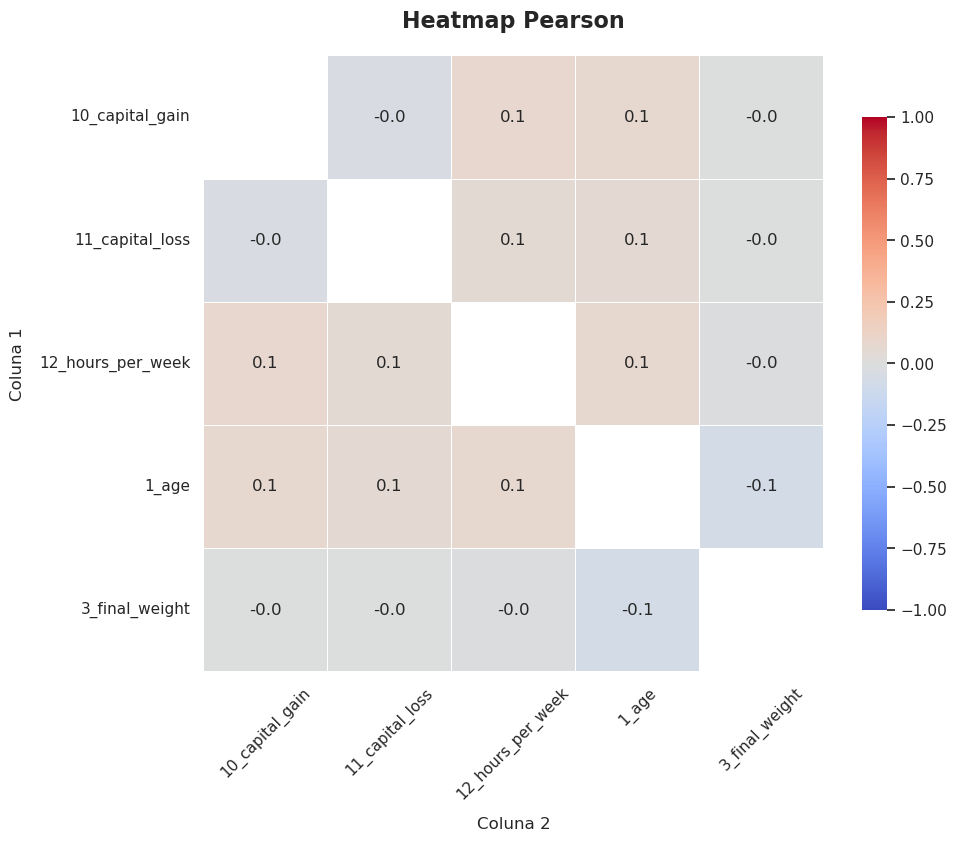

In [46]:
df_d07_quant_pearson_heatmap = df_d07_quant_pearson[['col_1', 'col_2', 'pearson_value']]
df_d07_quant_pearson_heatmap = df_d07_quant_pearson_heatmap.pivot(index="col_1", columns="col_2", values="pearson_value")

mask = np.eye(df_d07_quant_pearson_heatmap.shape[0], dtype=bool)

sns.set_theme(style="white")
plt.figure(figsize=(10, 8))

sns.heatmap(df_d07_quant_pearson_heatmap,mask=mask,  annot=True,  fmt=".1f",  cmap="coolwarm",  linewidths=0.5,  linecolor="white",  cbar_kws={"shrink": 0.8}, vmin=-1,vmax=1)

plt.title("Heatmap Pearson",fontsize=16,pad=20,weight="bold",)
plt.xlabel("Coluna 2", fontsize=12, labelpad=10)
plt.ylabel("Coluna 1", fontsize=12, labelpad=10)
plt.xticks(rotation=45)

plt.show()

In [49]:
df_d07_quant_spearman

,col_1,col_2,spearman_value
0,1_age,1_age,1.000000
1,1_age,3_final_weight,-0.077276
2,1_age,10_capital_gain,0.124305
3,1_age,11_capital_loss,0.057455
4,1_age,12_hours_per_week,0.146263
5,3_final_weight,1_age,-0.077276
6,3_final_weight,3_final_weight,1.000000
7,3_final_weight,10_capital_gain,-0.008754
8,3_final_weight,11_capital_loss,-0.000940
9,3_final_weight,12_hours_per_week,-0.016420


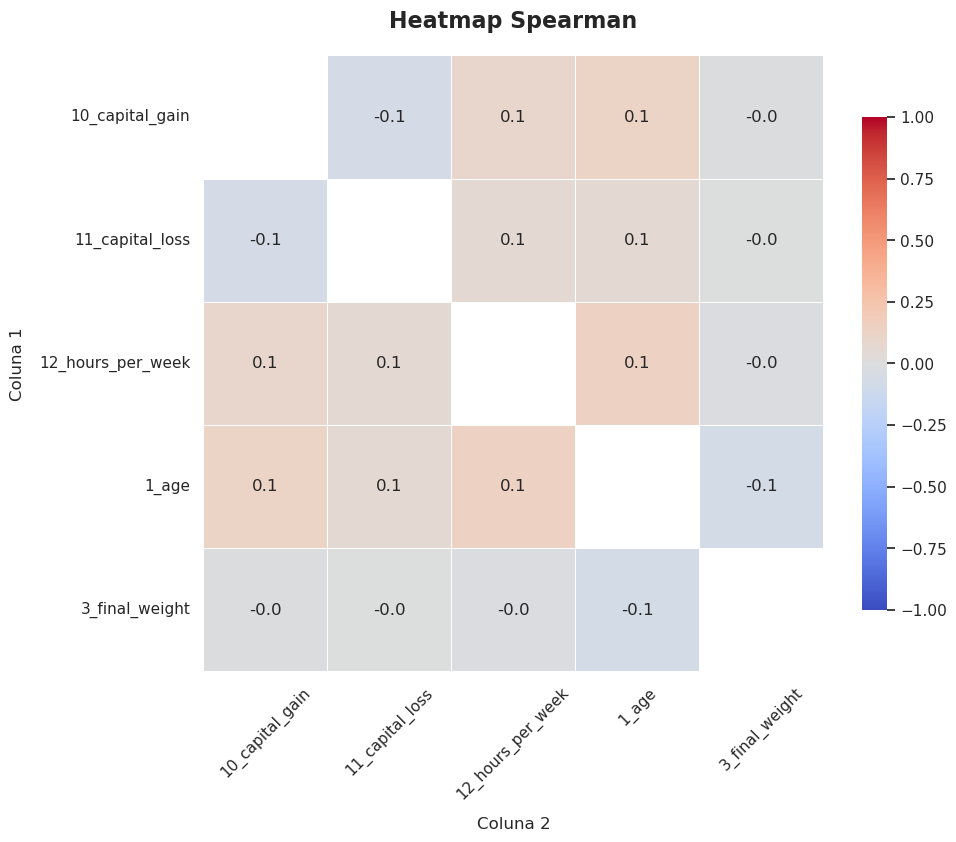

In [47]:
df_d07_quant_spearman_heatmap = df_d07_quant_spearman[['col_1', 'col_2', 'spearman_value']]
df_d07_quant_spearman_heatmap = df_d07_quant_spearman_heatmap.pivot(index="col_1", columns="col_2", values="spearman_value")

mask = np.eye(df_d07_quant_spearman_heatmap.shape[0], dtype=bool)

sns.set_theme(style="white")
plt.figure(figsize=(10, 8))

sns.heatmap(df_d07_quant_spearman_heatmap,mask=mask,  annot=True,  fmt=".1f",  cmap="coolwarm",  linewidths=0.5,  linecolor="white",  cbar_kws={"shrink": 0.8}, vmin=-1,vmax=1)

plt.title("Heatmap Spearman",fontsize=16,pad=20,weight="bold",)
plt.xlabel("Coluna 2", fontsize=12, labelpad=10)
plt.ylabel("Coluna 1", fontsize=12, labelpad=10)
plt.xticks(rotation=45)

plt.show()

In [50]:
df_d07_quant_kendall

,col_1,col_2,kendall_value
0,1_age,1_age,1.000000
1,1_age,3_final_weight,-0.052228
2,1_age,10_capital_gain,0.100569
3,1_age,11_capital_loss,0.046952
4,1_age,12_hours_per_week,0.110746
5,3_final_weight,1_age,-0.052228
6,3_final_weight,3_final_weight,1.000000
7,3_final_weight,10_capital_gain,-0.007000
8,3_final_weight,11_capital_loss,-0.000767
9,3_final_weight,12_hours_per_week,-0.011881


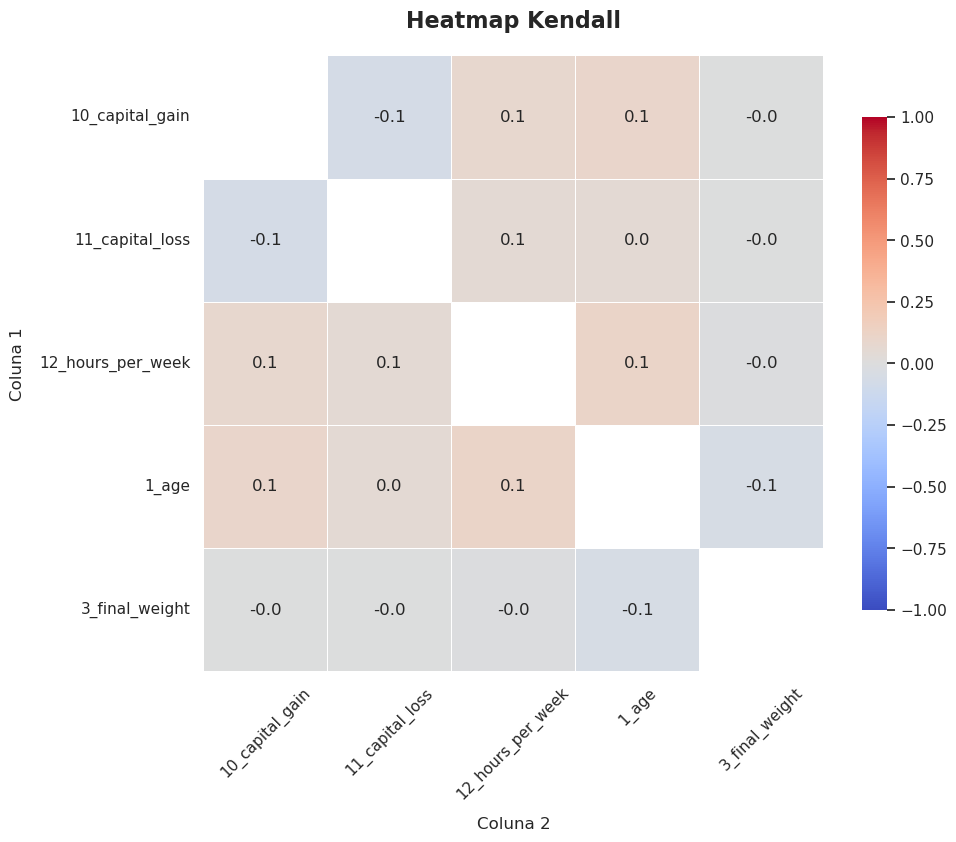

In [48]:
df_d07_quant_kendall_heatmap = df_d07_quant_kendall[['col_1', 'col_2', 'kendall_value']]
df_d07_quant_kendall_heatmap = df_d07_quant_kendall_heatmap.pivot(index="col_1", columns="col_2", values="kendall_value")

mask = np.eye(df_d07_quant_kendall_heatmap.shape[0], dtype=bool)

sns.set_theme(style="white")
plt.figure(figsize=(10, 8))

sns.heatmap(df_d07_quant_kendall_heatmap,mask=mask,  annot=True,  fmt=".1f",  cmap="coolwarm",  linewidths=0.5,  linecolor="white",  cbar_kws={"shrink": 0.8}, vmin=-1,vmax=1)

plt.title("Heatmap Kendall",fontsize=16,pad=20,weight="bold",)
plt.xlabel("Coluna 2", fontsize=12, labelpad=10)
plt.ylabel("Coluna 1", fontsize=12, labelpad=10)
plt.xticks(rotation=45)

plt.show()

#### *Análise qualitative / qualitativa*

In [31]:
df_v_cramer

,col_1,col_2,v_cramer,min_cohen
0,2_workclass,2_workclass,1.000000,8
1,2_workclass,4_education,0.100009,8
2,2_workclass,5_marital_status,0.085413,6
3,2_workclass,6_occupation,0.400122,8
4,2_workclass,7_relationship,0.100771,5
...,...,...,...,...
76,14_TARGET,7_relationship,0.454321,1
77,14_TARGET,8_race,0.099958,1
78,14_TARGET,9_sex,0.214639,1
79,14_TARGET,13_native_country,0.095975,1


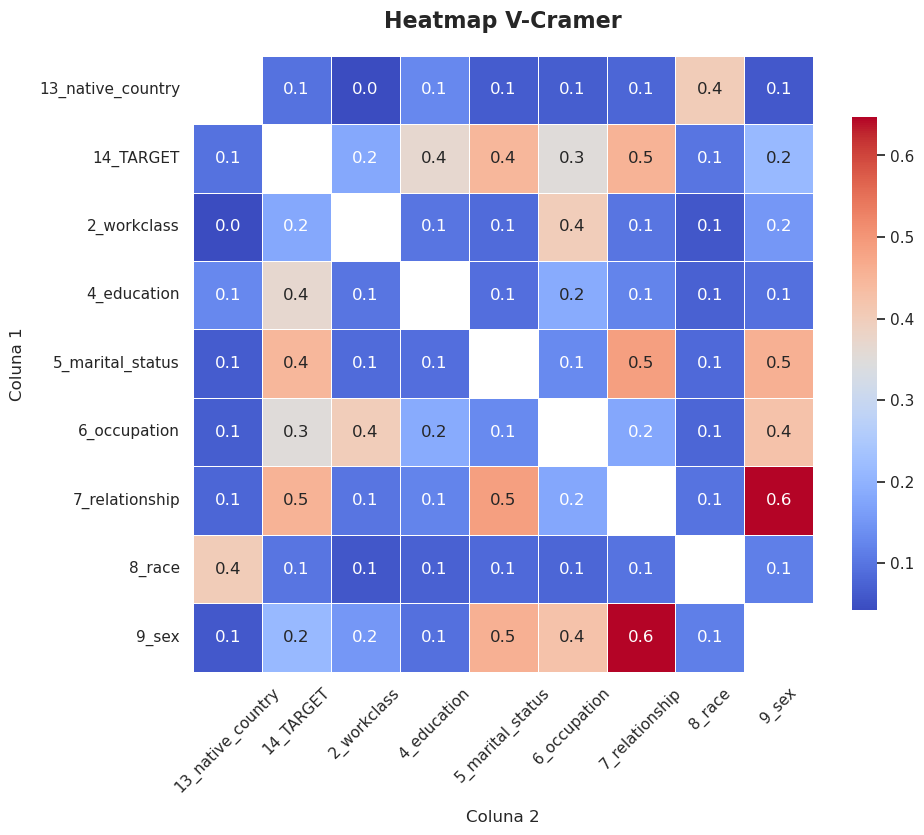

In [38]:
df_v_cramer_heatmap = df_v_cramer[['col_1', 'col_2', 'v_cramer']]
df_v_cramer_heatmap = df_v_cramer_heatmap.pivot(index="col_1", columns="col_2", values="v_cramer")

mask = np.eye(df_v_cramer_heatmap.shape[0], dtype=bool)

sns.set_theme(style="white")
plt.figure(figsize=(10, 8))

sns.heatmap(df_v_cramer_heatmap,mask=mask,  annot=True,  fmt=".1f",  cmap="coolwarm",  linewidths=0.5,  linecolor="white",  cbar_kws={"shrink": 0.8},  )

plt.title("Heatmap V-Cramer",fontsize=16,pad=20,weight="bold",)
plt.xlabel("Coluna 2", fontsize=12, labelpad=10)
plt.ylabel("Coluna 1", fontsize=12, labelpad=10)
plt.xticks(rotation=45)

plt.show()



| min(r-1, c-1) | Negligible |     Weak     |   Moderate   | Strong |
| :-----------: | :--------: | :----------: | :----------: | :----: |
|       1       |   < 0.10   | [0.10, 0.30) | [0.30, 0.50) | 0.50+  |
|       2       |   < 0.07   | [0.07, 0.21) | [0.21, 0.35) | 0.35+  |
|       3       |   < 0.06   | [0.06, 0.17) | [0.17, 0.29) | 0.29+  |
|       4       |   < 0.05   | [0.05, 0.15) | [0.15, 0.25) | 0.25+  |
|       5       |   < 0.05   | [0.05, 0.13) | [0.13, 0.22) | 0.22+  |

<small>Source: Cohen, J. (1988). Statistical power analysis for the behavioral sciences (2nd ed).</small>


In [36]:
# 7_relationship x 9_sex
df_v_cramer[(df_v_cramer["col_1"] == '9_sex') & (df_v_cramer["col_2"] == '7_relationship')]

,col_1,col_2,v_cramer,min_cohen
58,9_sex,7_relationship,0.646749,1


In [ ]:
# 8_race x 13_native_country
df_v_cramer[(df_v_cramer["col_1"] == '8_race') & (df_v_cramer["col_2"] == '13_native_country')]

,col_1,col_2,v_cramer,min_cohen
52,8_race,13_native_country,0.40171,4
